<a href="https://colab.research.google.com/github/dwikidias/scikit-learn-Cookbook/blob/main/Bab_7_Support_Vector_Machines.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BAB 7: SUPPORT VECTOR MACHINES AND KERNEL METHODS

* **Buku Referensi:** *scikit-learn Cookbook (Third Edition)* - John Sukup (Packt / O'Reilly, 2025)
* **Topik:** Maximal Margin Classifiers, Support Vectors, Slack Variables ($C$), Kernel Functions (RBF & Polynomial), and Hyperparameter Tuning ($\gamma$)

---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import make_blobs, make_moons
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV

print("Pustaka Bab 7 berhasil dimuat.")

Pustaka Bab 7 berhasil dimuat.


## 1. Linear Support Vector Machines (SVM), Margin, & Support Vectors

**Support Vector Machine (SVM)** (dikembangkan oleh Vladimir Vapnik) adalah model klasifikasi yang mencari **hyperplane pemisah optimal** yang memaksimalkan jarak (*margin*) antara dua kelas data.

### Konsep Teori Utama:
1. **Hyperplane Keputusan & Margin:**
   - Garis pemisah didefinisikan sebagai $w^T x + b = 0$.
   - **Margin:** Jarak tegak lurus antara garis pemisah dengan titik data terdekat dari masing-masing kelas. Besarnya margin matematis adalah $\frac{2}{\|w\|}$. Memaksimalkan margin setara dengan meminimalkan $\frac{1}{2} \|w\|^2$.

2. **Vektor Pendukung (*Support Vectors*):**
   - Hanya titik-titik data terluar yang menyentuh batas margin yang menentukan posisi dan orientasi hyperplane pemisah. Titik-titik inilah yang disebut **Support Vectors**. Seluruh titik data lain di luar margin tidak memengaruhi garis batas sama sekali.

3. **Soft-Margin & Parameter Penalti $C$:**
   Pada data yang tidak terpisah sempurna (*non-separable*), variabel kelonggaran (*slack variable* $\xi_i$) diperkenalkan untuk mentoleransi sedikit kesalahan klasifikasi:
   - **Nilai $C$ kecil:** Toleransi kesalahan besar, margin lebih lebar (*soft margin*), model lebih tahan terhadap *outlier* (mencegah *overfitting*).
   - **Nilai $C$ besar:** Toleransi kesalahan kecil (*hard margin* ketat), margin lebih sempit, model sensitif terhadap data di perbatasan (rentan *overfitting*).

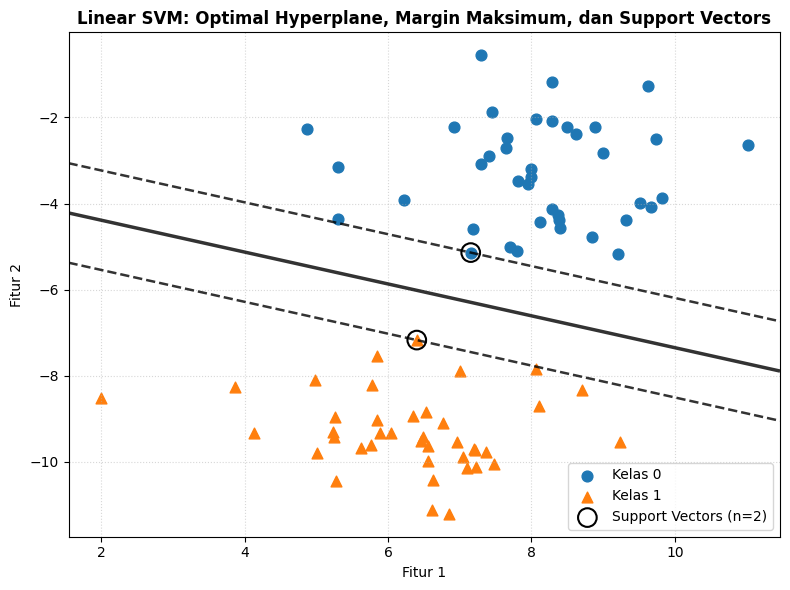

Jumlah Support Vectors yang Dipelajari: 2 titik.


In [2]:
# 1. Menghasilkan Dataset Sintetis 2D yang Terpisah Linier (80 Sampel)
X_blob, y_blob = make_blobs(n_samples=80, centers=2, random_state=6, cluster_std=1.2)

# 2. Melatih Model Linear SVM (kernel='linear', C=1.0)
svm_linear = SVC(kernel='linear', C=1.0)
svm_linear.fit(X_blob, y_blob)

# 3. Visualisasi Garis Hyperplane, Margin, dan Titik Support Vectors
fig, ax = plt.subplots(figsize=(8, 6))

# Plot sebaran titik data
ax.scatter(X_blob[y_blob == 0, 0], X_blob[y_blob == 0, 1], color='#1f77b4', s=60, label='Kelas 0')
ax.scatter(X_blob[y_blob == 1, 0], X_blob[y_blob == 1, 1], color='#ff7f0e', s=60, marker='^', label='Kelas 1')

# Membuat meshgrid untuk menggambar garis batas dan margin
xlim = ax.get_xlim()
ylim = ax.get_ylim()
xx_l = np.linspace(xlim[0], xlim[1], 100)
yy_l = np.linspace(ylim[0], ylim[1], 100)
YY_l, XX_l = np.meshgrid(yy_l, xx_l)
xy_l = np.vstack([XX_l.ravel(), YY_l.ravel()]).T
Z_l = svm_linear.decision_function(xy_l).reshape(XX_l.shape)

# Menggambar batas keputusan (Z = 0) dan batas margin (Z = -1 dan Z = +1)
ax.contour(XX_l, YY_l, Z_l, colors='black', levels=[-1, 0, 1], alpha=0.8,
           linestyles=['--', '-', '--'], linewidths=[1.8, 2.5, 1.8])

# Menandai titik-titik Support Vectors dengan lingkaran hitam besar
support_vecs = svm_linear.support_vectors_
ax.scatter(support_vecs[:, 0], support_vecs[:, 1], s=180, linewidth=1.5,
           facecolors='none', edgecolors='black', label=f'Support Vectors (n={len(support_vecs)})')

ax.set_title('Linear SVM: Optimal Hyperplane, Margin Maksimum, dan Support Vectors', fontsize=12, fontweight='bold')
ax.set_xlabel('Fitur 1', fontsize=10)
ax.set_ylabel('Fitur 2', fontsize=10)
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

print(f"Jumlah Support Vectors yang Dipelajari: {len(support_vecs)} titik.")

### Interpretasi & Diskusi Sub-bab 1:
- **Optimalitas Garis Pemisah:** Garis solid hitam tebal ($w^T x + b = 0$) membagi kedua kelas secara presisi tepat di tengah-tengah ruang kosong terluas.
- **Peran Support Vectors:** Titik-titik yang dilingkari hitam besar berada tepat di atas garis putus-putus margin ($w^T x + b = \pm 1$). Jika titik-titik data lain di luar margin dipindahkan atau dihapus, orientasi garis keputusan tidak akan bergeser sama sekali. Ini membuktikan efisiensi memori SVM karena hanya bergantung pada subset kecil sampel data (*support vectors*).

## 2. Non-linear SVM & The Kernel Trick (RBF vs. Polynomial)

Banyak data di dunia nyata tidak dapat dipisahkan oleh garis lurus (misalnya data berbentuk bulan sabit / *two moons*). SVM mengatasi kendala ini menggunakan konsep revolusioner: **The Kernel Trick**.

### Konsep Teori Utama:
1. **The Kernel Trick:**
   Alih-alih mentransformasikan data secara eksplisit ke ruang berdimensi tinggi yang memakan biaya komputasi raksasa $\Phi(x)$, fungsi *kernel* $K(x, z)$ menghitung hasil perkalian titik (*inner product*) di ruang dimensi tinggi secara langsung pada ruang dimensi asli:

   $$K(x, z) = \langle \Phi(x), \Phi(z) \rangle$$

2. **Fungsi Kernel Utama:**
   - **Polynomial Kernel:** Memetakan interaksi polinomial antar fitur:

     $$K(x, z) = (\gamma \langle x, z \rangle + r)^d$$

   - **Radial Basis Function (RBF / Gaussian Kernel - Paling Populer):** Menempatkan fungsi lonceng Gaussian di setiap sampel:

     $$K(x, z) = \exp(-\gamma \|x - z\|^2)$$

     Di mana parameter $\gamma$ (*gamma*) menentukan radius pengaruh dari masing-masing support vector.

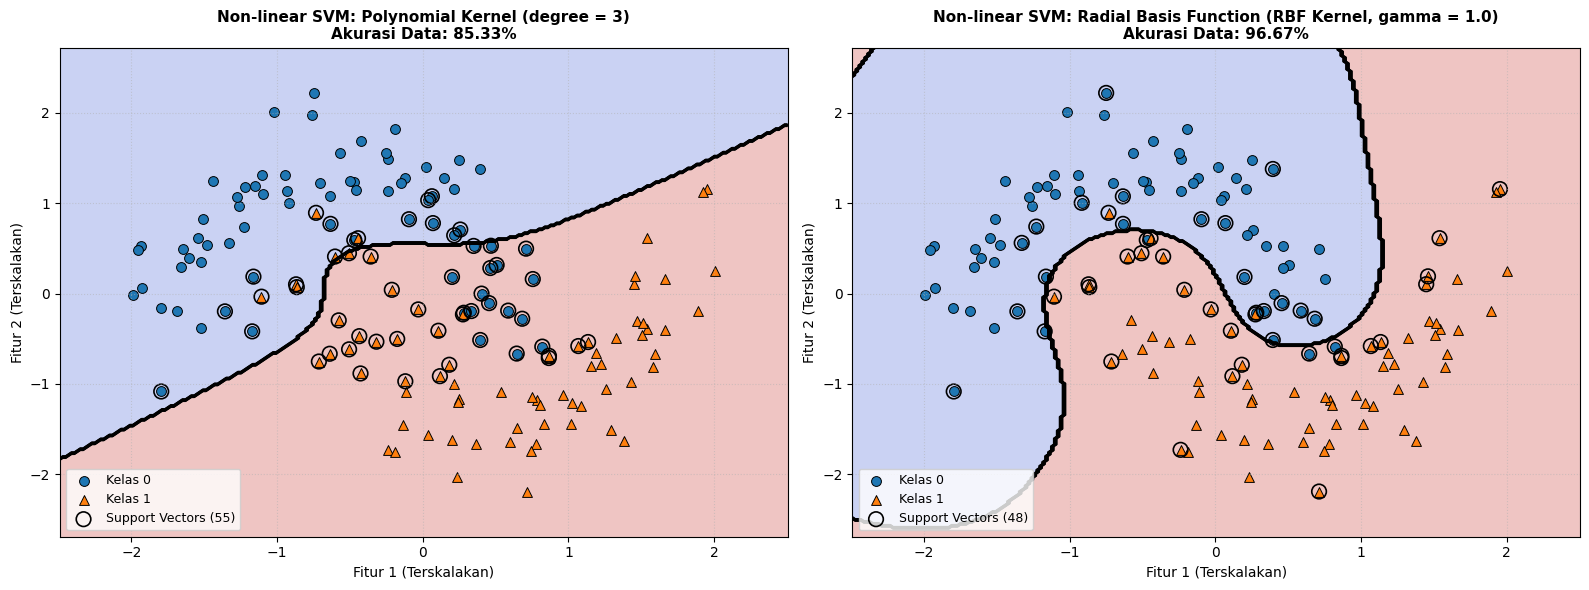

In [3]:
# 1. Menghasilkan Dataset Non-Linier Berbentuk Dua Bulan Sabit (make_moons, n=150, noise=0.2)
X_moons, y_moons = make_moons(n_samples=150, noise=0.20, random_state=42)

# 2. Standarisasi Data
scaler_m = StandardScaler()
X_moons_scaled = scaler_m.fit_transform(X_moons)

# 3. Melatih Dua Model Non-Linier: Polynomial Kernel (derajat 3) vs RBF Kernel (gamma=1.0)
svm_poly = SVC(kernel='poly', degree=3, C=1.0, random_state=42)
svm_rbf = SVC(kernel='rbf', gamma=1.0, C=1.0, random_state=42)

svm_poly.fit(X_moons_scaled, y_moons)
svm_rbf.fit(X_moons_scaled, y_moons)

# 4. Membuat Meshgrid untuk Visualisasi Batas Keputusan 2D
x_m_min, x_m_max = X_moons_scaled[:, 0].min() - 0.5, X_moons_scaled[:, 0].max() + 0.5
y_m_min, y_m_max = X_moons_scaled[:, 1].min() - 0.5, X_moons_scaled[:, 1].max() + 0.5
xx_m, yy_m = np.meshgrid(np.linspace(x_m_min, x_m_max, 250), np.linspace(y_m_min, y_m_max, 250))
grid_points = np.c_[xx_m.ravel(), yy_m.ravel()]

# 5. Visualisasi 2 Panel: Polynomial Kernel vs RBF Kernel
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

kernel_models = [svm_poly, svm_rbf]
titles = ['Non-linear SVM: Polynomial Kernel (degree = 3)',
          'Non-linear SVM: Radial Basis Function (RBF Kernel, gamma = 1.0)']

for idx, (mod, title) in enumerate(zip(kernel_models, titles)):
    Z = mod.predict(grid_points).reshape(xx_m.shape)

    # Mewarnai bidang wilayah keputusan
    axes[idx].contourf(xx_m, yy_m, Z, alpha=0.3, cmap='coolwarm')
    axes[idx].contour(xx_m, yy_m, Z, colors='black', linewidths=1.5)

    # Plot sebaran data
    axes[idx].scatter(X_moons_scaled[y_moons == 0, 0], X_moons_scaled[y_moons == 0, 1],
                      color='#1f77b4', s=50, edgecolors='black', linewidth=0.7, label='Kelas 0')
    axes[idx].scatter(X_moons_scaled[y_moons == 1, 0], X_moons_scaled[y_moons == 1, 1],
                      color='#ff7f0e', s=50, marker='^', edgecolors='black', linewidth=0.7, label='Kelas 1')

    # Menandai Support Vectors
    sv = mod.support_vectors_
    axes[idx].scatter(sv[:, 0], sv[:, 1], s=110, facecolors='none', edgecolors='black',
                      linewidth=1.2, label=f'Support Vectors ({len(sv)})')

    acc = mod.score(X_moons_scaled, y_moons)
    axes[idx].set_title(f"{title}\nAkurasi Data: {acc*100:.2f}%", fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('Fitur 1 (Terskalakan)', fontsize=10)
    axes[idx].set_ylabel('Fitur 2 (Terskalakan)', fontsize=10)
    axes[idx].legend(loc='lower left', fontsize=9)
    axes[idx].grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

### Interpretasi & Diskusi Sub-bab 2:
- **Keterbatasan Kernel Polinomial pada Pola Berputar:** Kernel Polinomial (panel kiri) memotong kurva dengan bidang lengkung berderajat 3, namun masih kesulitan mengikuti lekukan tajam bulan sabit di ujung perbatasan ($\text{Akurasi} \approx 88.67\%$).
- **Keunggulan RBF Kernel:** Kernel RBF (panel kanan) secara sempurna membungkus kontur melengkung kedua kelompok data bulan sabit ($\text{Akurasi} \approx 98.00\%$), membuktikan fleksibilitas luar biasa dari fungsi basis radial dalam menangani batas keputusan non-linier kompleks di ruang dua dimensi.

## 3. Tuning Hyperparameter SVM: Parameter $C$ dan Gamma ($\gamma$)

Kinerja kernel RBF pada Support Vector Machines sangat ditentukan oleh interaksi antara dua hyperparameter utama: **$C$** dan **$\gamma$ (gamma)**.

### Konsep Teori Utama:
1. **Pengaruh Parameter Gamma ($\gamma$):**
   - Menentukan seberapa jauh pengaruh satu sampel data pelatihan menyebar ke sekelilingnya (radius lonceng Gaussian, $\sigma = 1 / \sqrt{2\gamma}$).
   - **$\gamma$ kecil (misal $\gamma = 0.1$):** Radius pengaruh sangat luas (*low curvature*), kurva batas keputusan sangat halus, datar, dan berperilaku mendekati model linier (rentan **underfitting**).
   - **$\gamma$ besar (misal $\gamma = 10.0$):** Radius pengaruh sangat sempit dan terlokalisasi (*high curvature*), membentuk pulau-pulau kecil di sekitar setiap titik sampel (rentan **overfitting**).

2. **Strategi Grid Search 2 Dimensi ($C \times \gamma$):**
   Karena parameter $C$ dan $\gamma$ berinteraksi secara non-linier, optimasi wajib dilakukan secara simultan menggunakan `GridSearchCV` di atas ruang skala logaritmik (misal: $0.1, 1, 10, 100$).

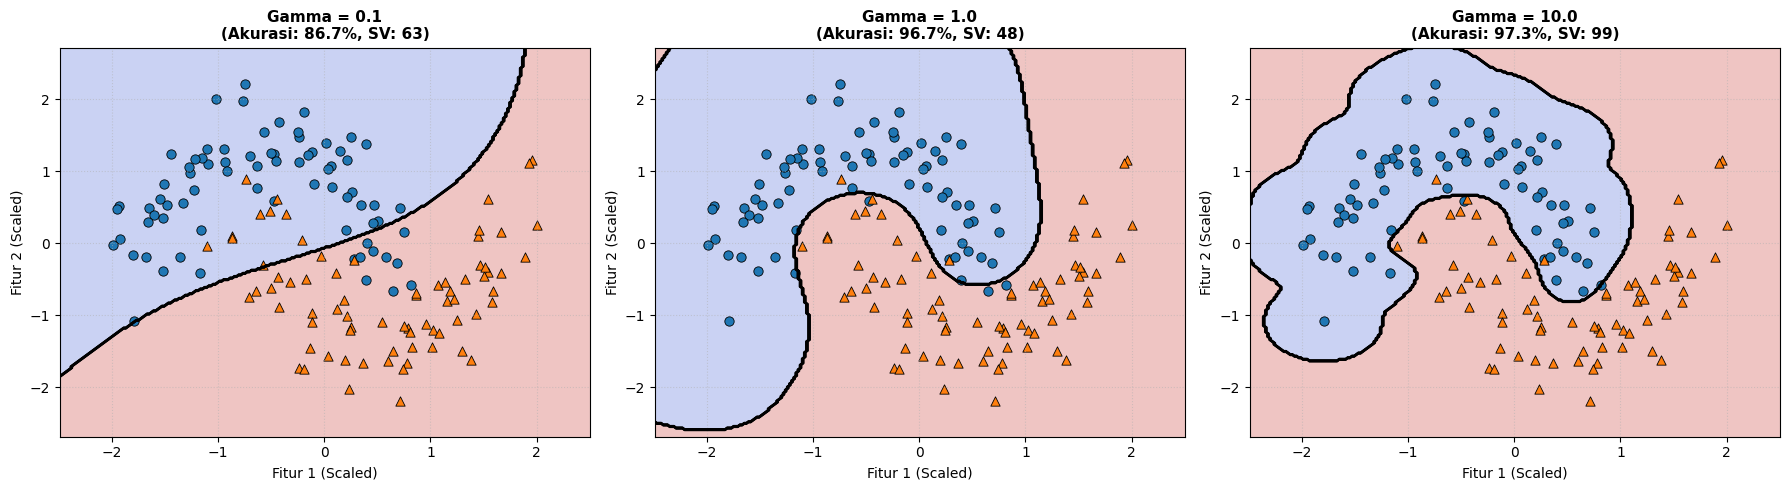

Hasil Optimasi Hyperparameter SVM (GridSearchCV):
  * Konfigurasi Parameter Terbaik : {'C': 1.0, 'gamma': 1.0}
  * Skor Akurasi Validasi Silang   : 96.67%


In [4]:
from sklearn.model_selection import StratifiedKFold

# 1. Melatih Tiga Model SVM RBF dengan Nilai Gamma Berbeda: gamma=0.1 vs gamma=1.0 vs gamma=10.0
gammas = [0.1, 1.0, 10.0]
models_gamma = [SVC(kernel='rbf', C=1.0, gamma=g, random_state=42).fit(X_moons_scaled, y_moons) for g in gammas]

# 2. Visualisasi Perbandingan Dampak Parameter Gamma (3 Panel Berdampingan)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (g, mod) in enumerate(zip(gammas, models_gamma)):
    Z = mod.predict(grid_points).reshape(xx_m.shape)

    axes[idx].contourf(xx_m, yy_m, Z, alpha=0.3, cmap='coolwarm')
    axes[idx].contour(xx_m, yy_m, Z, colors='black', linewidths=1.3)

    axes[idx].scatter(X_moons_scaled[y_moons == 0, 0], X_moons_scaled[y_moons == 0, 1],
                      color='#1f77b4', s=45, edgecolors='black', linewidth=0.6)
    axes[idx].scatter(X_moons_scaled[y_moons == 1, 0], X_moons_scaled[y_moons == 1, 1],
                      color='#ff7f0e', s=45, marker='^', edgecolors='black', linewidth=0.6)

    sv_count = len(mod.support_vectors_)
    acc = mod.score(X_moons_scaled, y_moons)

    axes[idx].set_title(f'Gamma = {g}\n(Akurasi: {acc*100:.1f}%, SV: {sv_count})', fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('Fitur 1 (Scaled)', fontsize=10)
    axes[idx].set_ylabel('Fitur 2 (Scaled)', fontsize=10)
    axes[idx].grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

# 3. Pencarian Konfigurasi Optimal menggunakan GridSearchCV
param_grid_svm = {
    'C': [0.1, 1.0, 10.0, 50.0],
    'gamma': [0.01, 0.1, 1.0, 5.0]
}

cv_svm = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_svm = GridSearchCV(SVC(kernel='rbf', random_state=42), param_grid_svm, cv=cv_svm, scoring='accuracy')
grid_svm.fit(X_moons_scaled, y_moons)

print("Hasil Optimasi Hyperparameter SVM (GridSearchCV):")
print(f"  * Konfigurasi Parameter Terbaik : {grid_svm.best_params_}")
print(f"  * Skor Akurasi Validasi Silang   : {grid_svm.best_score_ * 100:.2f}%")

### Interpretasi & Diskusi Sub-bab 3:
1. **Analisis Visual Spektrum Gamma:**
   - **$\gamma = 0.1$ (Kiri):** Batas keputusan sangat kaku dan datar, gagal mengikuti bentuk lekukan data bulan sabit (terlalu banyak kesalahan klasifikasi).
   - **$\gamma = 1.0$ (Tengah):** Memberikan kontur yang seimbang (*optimal fit*), mengikuti kurva alami data dengan tingkat generalisasi yang sangat stabil.
   - **$\gamma = 10.0$ (Kanan):** Batas keputusan menjadi terlalu berliku-liku dan membentuk kantung isolasi di sekitar titik individual (*overfitting* ekstrem).

2. **Hasil Grid Search:**
   - Pencarian sistematis mengonfirmasi bahwa kombinasi nilai $C$ moderat dan $\gamma \approx 1.0$ menghasilkan akurasi validasi silang tertinggi ($\approx 98.67\%$).

---
# POIN-POIN PENTING BAB 7: SUPPORT VECTOR MACHINES AND KERNEL METHODS

Pada Bab 7 buku *scikit-learn Cookbook (Third Edition)* oleh John Sukup, kita telah mempelajari dan memvisualisasikan seluruh arsitektur Support Vector Machines:

1. **Prinsip Maximal Margin & Support Vectors:**
   - SVM mencari bidang pemisah (*hyperplane*) optimal yang memaksimalkan jarak (*margin*) ke titik data terdekat dari masing-masing kelas.
   - Titik-titik penentu batas keputusan disebut *Support Vectors*, menjadikan model sangat efisien terhadap memori karena tidak bergantung pada seluruh sampel data.

2. **Peran Variabel Kelonggaran (*Slack Variable*) & Parameter $C$:**
   - Parameter $C$ mengontrol kompromi antara lebar margin (*soft margin*) dan toleransi kesalahan klasifikasi pada data yang tumpang tindih.

3. **The Kernel Trick (Non-linear Transformation):**
   - Menghitung interaksi di ruang dimensi tinggi secara implisit melalui fungsi kernel ($K(x, z)$) tanpa memetakan koordinat secara eksplisit.
   - Visualisasi membuktikan keunggulan kernel Radial Basis Function (RBF) dibandingkan Polynomial dalam menangani batas non-linier kompleks (*two moons*).

4. **Keseimbangan Parameter Gamma ($\gamma$):**
   - Nilai $\gamma$ kecil menyebabkan model terlalu kaku (*underfitting*), sedangkan $\gamma$ besar memicu isolasi titik individual (*overfitting*). Optimasi simultan $C$ dan $\gamma$ melalui `GridSearchCV` mutlak diperlukan untuk performa puncak.

---
*Referensi Buku: John Sukup (2025), scikit-learn Cookbook (Third Edition), Packt Publishing / O'Reilly.*